# 18 - The phase plane and nonlinear systems

**MATH 331 - Differential Equations.** Lecture plan, Unit 9: Session 19 (Sections 2-4) and Session 20
(Sections 5-7).

**References:** J. Lebl, *Notes on Diffy Qs*, Sections 3.5, 8.1-8.3 and exercises of Chapters 3 and 8;
notebooks 03, 04, 07, 09, 12, 17 (07E, optional); videos R05, R07, R09.

**What you will learn**
1. For $\vec{x}\,' = A\vec{x}$ ($2 \times 2$, constant), the picture near the origin is decided by the
   eigenvalues of $A$, read off from its trace and determinant (on the borderlines, with a look at $A$).
2. To draw phase portraits in Python.
3. Near an equilibrium, a nonlinear system $x' = f(x, y)$, $y' = g(x, y)$ has the stability and the kind
   of picture of its linearization whenever no eigenvalue of its Jacobian matrix has real part 0.

## 1. Theory in brief

**The phase plane.** In $x' = f(x, y)$, $y' = g(x, y)$ both unknowns are functions of $t$, and here
$y' = dy/dt$ (elsewhere in the course $y' = dy/dx$). Each solution is a curve, a **trajectory**, in the
**phase plane**. $t$ is not drawn: the point $(x(t), y(t))$ moves along the curve as $t$ grows, and an
arrow says which way. (For $x'' = \dots$ written as $x' = y$, $y' = \dots$, notebook 17, it is the plane
of $(x, x')$.) The **direction field** (Lebl 3.1.3) has at each point an arrow along $(f, g)$ (notebook
09 drew segments; here arrows, as the point can move left as well as right), all of one length on the
screen: directions, not speeds.

**Equilibria.** A point $(x^*, y^*)$ where $f = g = 0$ is a constant solution (Lebl: a *critical point*
$(x_0, y_0)$; here 0 marks a start). It is (Lebl 8.2.2)
* **stable** if every solution that starts close enough to it stays close to it for all later $t$;
* **asymptotically stable** if, in addition, those solutions tend to it as $t \to \infty$;
* **unstable** if it is not stable.

Notebook 03's "stable" (both arrows of the phase line point to $x^*$) is Lebl's *asymptotically stable*.
On a line the two words agree; in the plane, around a center, solutions stay close but go round for ever:
stable, not asymptotically stable.

**Linear systems** $\vec{x}\,' = A\vec{x}$, $\vec{x} = (x, y)$ (notebook 17). The origin is an
equilibrium. The eigenvalues solve $\lambda^2 - (\operatorname{tr} A)\lambda + \det A = 0$
($\operatorname{tr} A = a_{11} + a_{22}$, $\det A = a_{11}a_{22} - a_{12}a_{21}$); comparing with
$(\lambda - \lambda_1)(\lambda - \lambda_2)
= \lambda^2 - (\lambda_1 + \lambda_2)\lambda + \lambda_1\lambda_2$:

$$ \lambda_1 + \lambda_2 = \operatorname{tr} A, \qquad \lambda_1\lambda_2 = \det A . $$

A complex pair $\alpha \pm i\beta$ (notebook 17) thus has $\alpha = \operatorname{tr} A / 2$. Lebl's Table
3.5.1 ($\det A \ne 0$; Section 3 reads it from $\operatorname{tr} A$ and $\det A$):

| Eigenvalues | Picture (Lebl's words) |
|---|---|
| real, both positive | **source** (unstable node) |
| real, both negative | **sink** (stable node) |
| real, opposite signs | **saddle** |
| purely imaginary | **center** (ellipses) |
| complex, positive real part | **spiral source** |
| complex, negative real part | **spiral sink** |

**Nonlinear systems.** $f_x = \partial f/\partial x$ is the derivative of $f$ in $x$ with $y$ held fixed
(notebook 12). The **Jacobian matrix** at $(x^*, y^*)$ is

$$ J = \begin{pmatrix} f_x & f_y \\ g_x & g_y \end{pmatrix} \text{ at } (x^*, y^*) . $$

With $u_1 = x - x^*$, $u_2 = y - y^*$ (not the $u_1$, $u_2$ of notebooks 14 and 17): moving $x$ alone by
$u_1$ changes $f$ by about $f_xu_1$ (the tangent line of video R09), moving $y$ alone by about $f_yu_2$,
so $f(x, y) \approx f(x^*, y^*) + f_xu_1 + f_yu_2 = f_xu_1 + f_yu_2$ ($f = 0$ at an equilibrium); the same
for $g$. As $u_1' = x' = f$: near the equilibrium $\vec{u}\,' = J\vec{u}$, the **linearization** (Lebl
8.1.2, with $u$, $v$). Entries of $A$ and $J$: 1/time when $x$ and $y$ have the same units.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: classify_linear_2d, jacobian, classify_equilibrium_2d, trajectories, direction_field,
# phase_portrait, two_by_two_case, check, check_vector, check_choice).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. Pictures of $\vec{x}\,' = A\vec{x}$

**Conventions (every phase plane of this notebook).** $x$ across, positive to the right; $y$ up,
positive upwards; an arrow on a trajectory points towards increasing $t$. Lebl's examples of Sections
3.5, 8.1 and 8.2 have no units.

*Lebl, Section 3.5, Case 3:* $A = \begin{pmatrix} 1 & 1 \\ 0 & -2 \end{pmatrix}$. It is triangular, so
its eigenvalues are the diagonal entries 1 and $-2$; the shortcut $(a_{12}, \lambda - a_{11})$ gives the
eigenvectors $(1, 0)$ for 1 and $(1, -3)$ for $-2$ (notebook 17, Section 2). So there are two
**straight-line solutions**, $(1, 0)e^{t}$ and $(1, -3)e^{-2t}$.

**Why straight lines.** On the line of an eigenvector $\vec{v}$, $(x, y) = a\vec{v}$, and
$(x', y') = A(a\vec{v}) = a\lambda\vec{v}$: the arrow lies along the line, away from the origin when
$\lambda > 0$, towards it when $\lambda < 0$. Every other solution, $C_1(1, 0)e^{t} + C_2(1, -3)e^{-2t}$,
comes in along the second line and leaves along the first ($e^{-2t}$ dies, $e^{t}$ takes over): a
**saddle**.

In [2]:
def describe(eigenvalues):
    # the two eigenvalues as a student writes them
    first, second = eigenvalues
    if isinstance(first, complex) and first.real == 0:
        return f"+- {abs(first.imag):.3g}i"
    if isinstance(first, complex):
        return f"{first.real + 0.0:.3g} +- {abs(first.imag):.3g}i"       # + 0.0 turns -0.0 into 0.0
    if first == second:
        return f"{first + 0.0:.3g} (twice)"
    return f"{first + 0.0:.3g} and {second + 0.0:.3g}"


def report(name, phase):
    # what ol.classify_linear_2d found, in one line
    # (phase.kind, phase.stability, ...: the fields of what classify_linear_2d returns)
    print(f"{name}: {phase.kind} ({phase.stability}): tr {phase.trace + 0.0:.3g}, "
          f"det {phase.determinant + 0.0:.3g}, eigenvalues {describe(phase.eigenvalues)}")


def linear_field(A):
    # linear_field(A) is itself a function: give it x and y, it returns (x', y') of x' = A x
    (a11, a12), (a21, a22) = np.asarray(A, dtype=float)

    def field(x, y):
        return a11 * x + a12 * y, a21 * x + a22 * y

    return field


CASE_3 = np.array([[1.0, 1.0], [0.0, -2.0]])            # Lebl, Section 3.5, Case 3 (no units)
report("Case 3", ol.classify_linear_2d(CASE_3))
case_3 = ol.two_by_two_case(CASE_3)                     # the eigenvectors, as in notebook 17
for value, vector in zip(case_3.eigenvalues, case_3.eigenvectors):
    direction = vector / vector[0]                      # first entry 1, as written above
    print(f"eigenvalue {value:g}: eigenvector {direction.tolist()}, A v = {(CASE_3 @ direction).tolist()}")
assert sorted(case_3.eigenvalues) == [-2, 1]                                         # the values of the book
assert np.allclose([vector / vector[0] for vector in case_3.eigenvectors], [[1, -3], [1, 0]])

Case 3: saddle (unstable): tr -1, det -2, eigenvalues -2 and 1
eigenvalue -2: eigenvector [1.0, -3.0], A v = [-2.0, 6.0]
eigenvalue 1: eigenvector [1.0, 0.0], A v = [1.0, 0.0]


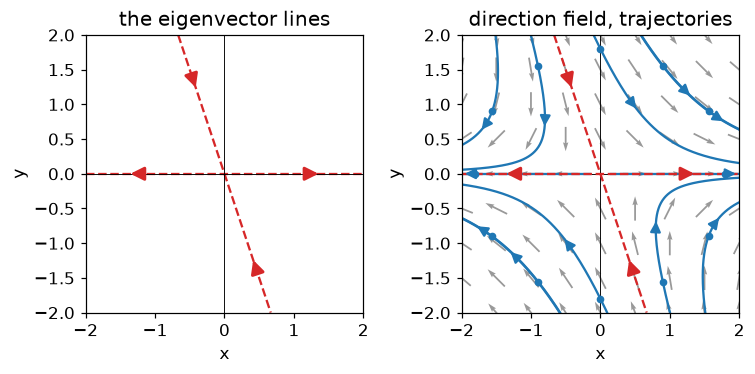

In [3]:
# drawing code: you can skip reading it
SQUARE = (-2.0, 2.0)                    # the window of the linear pictures, in x and in y
PAIR_FIGURE = (7.0, 3.8)                # two square phase planes side by side
N_STARTS = 12                           # starts on a circle, for the linear pictures
START_RADIUS = 1.8
ANGLES = np.linspace(0.0, 2 * np.pi, N_STARTS, endpoint=False)
CIRCLE_STARTS = START_RADIUS * np.column_stack([np.cos(ANGLES), np.sin(ANGLES)])
T_LINEAR = 2.5                          # each trajectory is followed for this time, both ways
ARROW_PLACES = (-0.65, 0.65)            # where the arrows sit on an eigenvector line, along the window
ARROW_SPAN = 0.05                       # an arrow on a line spans this part of it
ARROW_SIZE = 18                         # the size of its head (points)
FIELD_ARROWS = 9                        # arrows per side of a direction field (fewer than the library's 17)


def plane_axes(ax, title, x_label="x", y_label="y", equal=True):
    # the axes of a phase plane: the lines x = 0 and y = 0 (no grid: the arrows fill the plane), labels, title
    # (called before ol.direction_field, which measures the shape of the axes to draw arrows of one length)
    ax.grid(False)
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.axvline(0.0, color="black", linewidth=0.6)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    if equal:
        ax.set_aspect("equal")                          # x and y in the same units


def draw_eigenlines(ax, A, window=SQUARE):
    # the line of each real eigenvector (dashed), with arrows: outwards if lambda > 0, inwards if < 0
    case = ol.two_by_two_case(A)
    if case.case == ol.CASE_COMPLEX:
        return
    for value, vector in zip(case.eigenvalues, case.eigenvectors):
        direction = vector / np.max(np.abs(vector)) * window[1]     # reaches the edge of the window
        ax.plot([-direction[0], direction[0]], [-direction[1], direction[1]], "--", color="C3", linewidth=1.5)
        for place in ARROW_PLACES:
            middle = place * direction
            step = np.sign(value) * np.sign(place) * ARROW_SPAN * direction   # away from 0 when lambda > 0
            if value != 0:
                ax.annotate("", xy=tuple(middle + step), xytext=tuple(middle - step),
                            arrowprops={"arrowstyle": "-|>", "color": "C3", "lw": 2,
                                        "mutation_scale": ARROW_SIZE})


fig, (lines, picture) = plt.subplots(1, 2, figsize=PAIR_FIGURE)
draw_eigenlines(lines, CASE_3)
lines.set_xlim(*SQUARE)
lines.set_ylim(*SQUARE)
plane_axes(lines, "the eigenvector lines")
plane_axes(picture, "direction field, trajectories")
ol.direction_field(picture, linear_field(CASE_3), SQUARE, SQUARE, FIELD_ARROWS)   # last: arrows per side
ol.phase_portrait(picture, linear_field(CASE_3), CIRCLE_STARTS, (0.0, T_LINEAR), SQUARE, SQUARE)
draw_eigenlines(picture, CASE_3)
plt.tight_layout()
plt.show()

*The plot shows*, left, the eigenvector lines (dashed, as Lebl's Figure 3.5.2 for Case 1): arrows out
along $(1, 0)$, in along $(1, -3)$; right, Lebl's Figure 3.5.5: the direction field and twelve
trajectories (a dot at each start; the two on the $x$ axis stay on it).

**The six pictures** of Lebl's Cases 1-6, each titled by `ol.classify_linear_2d`:

Case 1: source (unstable): tr 3, det 2, eigenvalues 1 and 2
Case 2: sink (asymptotically stable): tr -3, det 2, eigenvalues -2 and -1
Case 3: saddle (unstable): tr -1, det -2, eigenvalues -2 and 1


Case 4: center (stable): tr 0, det 4, eigenvalues +- 2i
Case 5: spiral source (unstable): tr 2, det 5, eigenvalues 1 +- 2i
Case 6: spiral sink (asymptotically stable): tr -2, det 5, eigenvalues -1 +- 2i


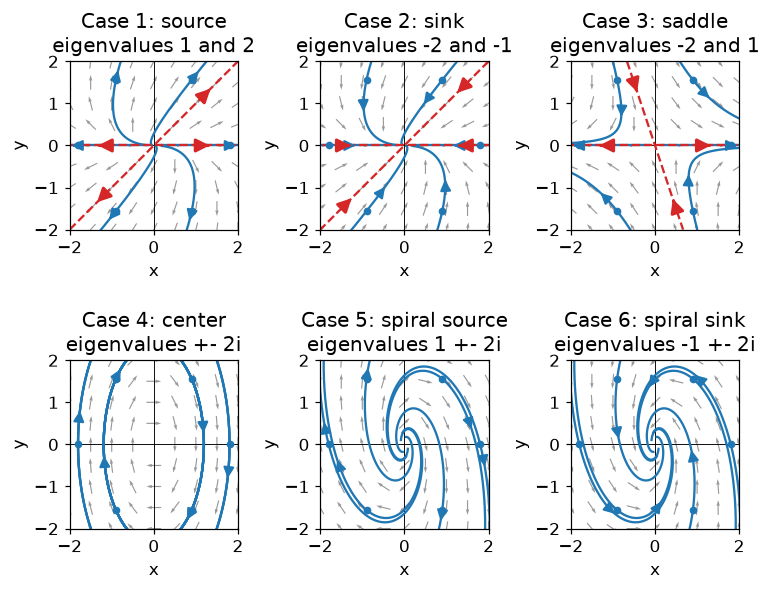

In [4]:
LEBL_CASES = {                                          # Lebl, Section 3.5, Cases 1-6 (no units)
    1: [[1, 1], [0, 2]], 2: [[-1, -1], [0, -2]], 3: [[1, 1], [0, -2]],
    4: [[0, 1], [-4, 0]], 5: [[1, 1], [-4, 1]], 6: [[-1, -1], [4, -1]],
}
SIX_FIGURE = (7.0, 5.6)                                 # two rows of three square pictures
FEW_ARROWS = 9                                          # arrows per side in these smaller pictures
FEW_STARTS = CIRCLE_STARTS[::2]                         # every second start: six of the twelve
fig, panels = plt.subplots(2, 3, figsize=SIX_FIGURE)
phases = {}
for (number, A), ax in zip(LEBL_CASES.items(), panels.ravel()):    # .ravel(): the six panels in one row
    phases[number] = ol.classify_linear_2d(A)
    report(f"Case {number}", phases[number])
    title = f"Case {number}: {phases[number].kind}\neigenvalues {describe(phases[number].eigenvalues)}"
    plane_axes(ax, title)
    ol.direction_field(ax, linear_field(A), SQUARE, SQUARE, FEW_ARROWS)
    ol.phase_portrait(ax, linear_field(A), FEW_STARTS, (0.0, T_LINEAR), SQUARE, SQUARE)
    draw_eigenlines(ax, A)
plt.tight_layout()
plt.show()
BOOK_KINDS = ["source", "sink", "saddle", "center", "spiral source", "spiral sink"]   # Lebl, Table 3.5.1
assert [phase.kind for phase in phases.values()] == BOOK_KINDS                       # the values of the book

*The plot shows* Lebl's Figures 3.5.3-3.5.8. Top row, real eigenvalues, dashed straight-line solutions:
trajectories leave the source, arrive at the sink, pass the saddle. Bottom row, complex: they turn
clockwise, on closed ellipses (real part 0), spiralling out (real part $> 0$) or in ($< 0$).

## 3. The trace-determinant plane

(The theory exercise of Session 19.) The quadratic formula gives
$\lambda = \big(\operatorname{tr} A \pm \sqrt{(\operatorname{tr} A)^2 - 4\det A}\big)/2$: the eigenvalues
are complex exactly when the discriminant $(\operatorname{tr} A)^2 - 4\det A$ is negative, and then
$\alpha \pm i\beta$ with $\alpha = \operatorname{tr} A/2$ and
$\lambda_1\lambda_2 = (\alpha + i\beta)(\alpha - i\beta) = \alpha^2 + \beta^2 > 0$. With Section 1's
$\lambda_1 + \lambda_2 = \operatorname{tr} A$ and $\lambda_1\lambda_2 = \det A$:
* $\det A < 0$: a negative product, so not complex, and of opposite signs: a **saddle**.
* $\det A > 0$ and $(\operatorname{tr} A)^2 > 4\det A$: real, with the same sign, the sign of their sum
  $\operatorname{tr} A$: a **source** if $\operatorname{tr} A > 0$, a **sink** if $\operatorname{tr} A < 0$.
* $(\operatorname{tr} A)^2 < 4\det A$ (so $\det A > 0$): complex with real part $\operatorname{tr} A/2$: a
  **spiral source** if $\operatorname{tr} A > 0$, a **spiral sink** if $\operatorname{tr} A < 0$, a
  **center** if $\operatorname{tr} A = 0$.
* The borderlines: on the parabola $(\operatorname{tr} A)^2 = 4\det A$ one eigenvalue $\operatorname{tr} A/2$
  twice (one eigenvector, as for Lebl's Exercise 3.5.2, $\begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}$,
  or $A = \lambda I$); on the axis $\det A = 0$ an eigenvalue 0, so $A\vec{x} = \vec{0}$ has nonzero
  solutions: at least a line of equilibria (the whole plane if $A = 0$; Exercise 3.5.3,
  $\begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}$). `ol.classify_linear_2d` calls these a **degenerate**
  source or sink (one eigenvector), a **star** source or sink ($A = \lambda I$), a **line of equilibria**
  (**parallel lines** if also $\operatorname{tr} A = 0$); Lebl calls the first two a source or a sink.
* Stability: the origin is asymptotically stable exactly when both eigenvalues (or their real parts)
  are negative, that is, when $\operatorname{tr} A < 0$ and $\det A > 0$. A center is stable but not
  asymptotically stable.

Exercise 3.5.2: degenerate source (unstable): tr 2, det 1, eigenvalues 1 (twice)
Exercise 3.5.3: line of equilibria (unstable): tr 2, det 0, eigenvalues 0 and 2


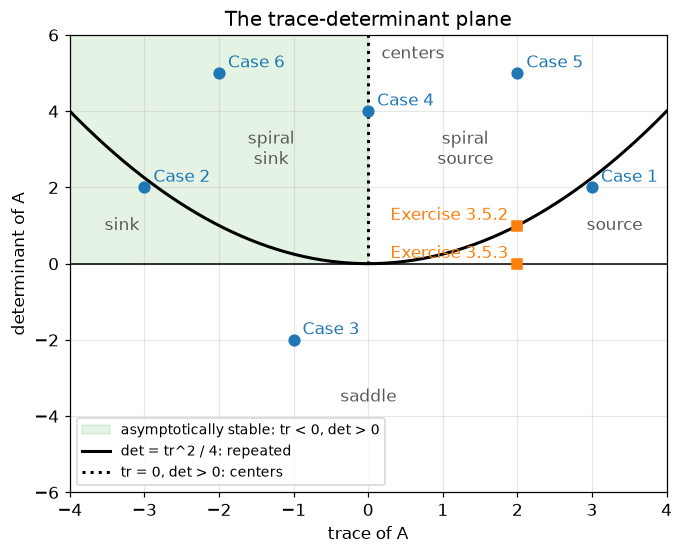

In [5]:
# drawing code: you can skip reading it
PLANE_FIGURE = (7.0, 5.4)
TRACE_WINDOW = (-4.0, 4.0)
DET_WINDOW = (-6.0, 6.0)                # room below for the legend
PARABOLA_POINTS = 200
PARABOLA = np.linspace(*TRACE_WINDOW, PARABOLA_POINTS)
POINT_SIZE = 7                          # markers: a point of the plane
MOVING_SIZE = 9                         # the point of the slider
STAR_SIZE = 11                          # an equilibrium (a black star)
LABEL_SHIFT = (0.12, 0.15)              # a label beside its point
REGION_LABELS = (("saddle", (0.0, -3.5)), ("source", (3.3, 1.0)), ("sink", (-3.3, 1.0)),
                 ("spiral\nsource", (1.3, 3.0)), ("spiral\nsink", (-1.3, 3.0)), ("centers", (0.6, 5.5)))
BORDERLINES = {"Exercise 3.5.2": [[1, 1], [0, 1]], "Exercise 3.5.3": [[1, 1], [1, 1]]}


def trace_det_plane(ax):
    # the parabola det = tr^2 / 4, the axes, the names of the regions, the stable quarter shaded
    ax.fill_between([TRACE_WINDOW[0], 0.0], 0.0, DET_WINDOW[1], color="C2", alpha=0.12,
                    label="asymptotically stable: tr < 0, det > 0")
    ax.plot(PARABOLA, PARABOLA ** 2 / 4, "-", color="black", linewidth=2, label="det = tr^2 / 4: repeated")
    ax.axhline(0.0, color="black", linewidth=1)
    ax.plot([0.0, 0.0], [0.0, DET_WINDOW[1]], ":", color="black", linewidth=2,
            label="tr = 0, det > 0: centers")
    for name, place in REGION_LABELS:
        ax.text(*place, name, ha="center", va="center", color="0.35")
    ax.set_xlim(*TRACE_WINDOW)
    ax.set_ylim(*DET_WINDOW)
    ax.set_xlabel("trace of A")
    ax.set_ylabel("determinant of A")


fig, ax = plt.subplots(figsize=PLANE_FIGURE)
trace_det_plane(ax)
for number, phase in phases.items():
    ax.plot(phase.trace, phase.determinant, "o", color="C0", markersize=POINT_SIZE)
    ax.text(phase.trace + LABEL_SHIFT[0], phase.determinant + LABEL_SHIFT[1], f"Case {number}", color="C0")
for name, A in BORDERLINES.items():
    phase = ol.classify_linear_2d(A)
    report(name, phase)
    ax.plot(phase.trace, phase.determinant, "s", color="C1", markersize=POINT_SIZE)
    ax.text(phase.trace - LABEL_SHIFT[0], phase.determinant + LABEL_SHIFT[1], name, color="C1", ha="right")
ax.set_title("The trace-determinant plane")
ax.legend(loc="lower left")
plt.show()

*The plot shows* the parabola (solid), the half-axis of centers (dotted), the six cases in their
regions, Exercises 3.5.2 and 3.5.3 on the borderlines, and, shaded, where the origin is asymptotically
stable.

**Slider: moving through the plane.** $A = \begin{pmatrix} -1 & 1 \\ p & -1 \end{pmatrix}$ (no units):
$\operatorname{tr} A = -2$, $\det A = 1 - p$, discriminant $4p$. Before moving it: at which $p$ does the
picture change its kind, and for which $p$ does the origin stop attracting every solution?

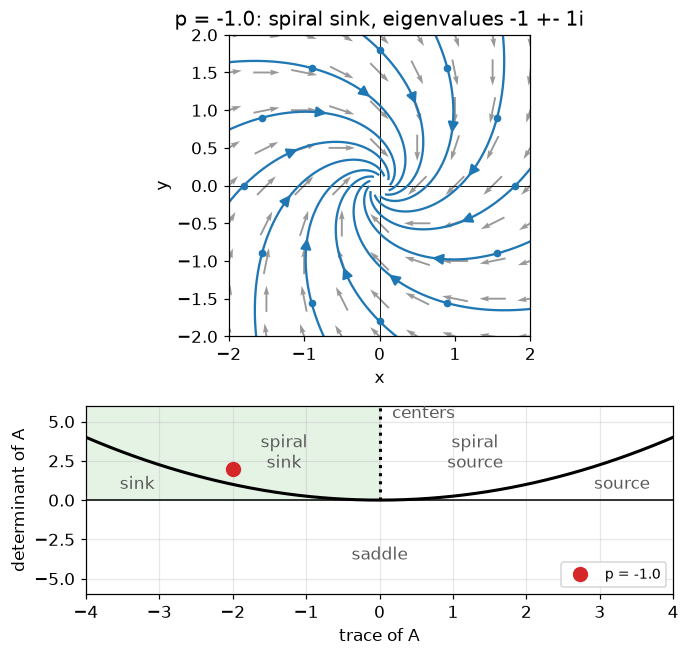

In [6]:
DEFAULT_P = -1.0
P_RANGE = (-3.0, 3.0, 0.1)              # minimum, maximum, step
FAMILY_FIGURE = (6.4, 6.1)              # the picture above, the plane below


def plot_family(p=DEFAULT_P):
    # x' = A x with A = [[-1, 1], [p, -1]] (a number p): its picture and its point (tr, det) = (-2, 1 - p)
    A = np.array([[-1.0, 1.0], [p, -1.0]])
    phase = ol.classify_linear_2d(A)
    fig, (picture, plane) = plt.subplots(2, 1, figsize=FAMILY_FIGURE,
                                         gridspec_kw={"height_ratios": [1.6, 1]})
    plane_axes(picture, f"p = {p:.1f}: {phase.kind}, eigenvalues {describe(phase.eigenvalues)}")
    ol.direction_field(picture, linear_field(A), SQUARE, SQUARE, FIELD_ARROWS)
    ol.phase_portrait(picture, linear_field(A), CIRCLE_STARTS, (0.0, T_LINEAR), SQUARE, SQUARE)
    draw_eigenlines(picture, A)                        # nothing for complex eigenvalues
    trace_det_plane(plane)
    (moving,) = plane.plot(phase.trace, phase.determinant, "o", color="C3", markersize=MOVING_SIZE,
                           label=f"p = {p:.1f}")       # (moving,) = the one line that plot returns
    plane.legend(handles=[moving], loc="lower right")  # only the point: the rest is explained in Section 3
    plt.tight_layout()
    plt.show()


plot_family()

In [7]:
interact(plot_family, p=FloatSlider(value=DEFAULT_P, min=P_RANGE[0], max=P_RANGE[1], step=P_RANGE[2],
                                    description="p", continuous_update=False));

interactive(children=(FloatSlider(value=-1.0, continuous_update=False, description='p', max=3.0, min=-3.0), Ou...

*The static plot shows*, for $p = -1$, a spiral sink (eigenvalues $-1 \pm i$): the trajectories turn
clockwise into the origin; below, the point $(-2, 2)$ above the parabola.

(Answer: a spiral sink for $p < 0$; at $p = 0$ the point is on the parabola: the eigenvalue $-1$ twice,
the two eigenvector lines $(1, \pm\sqrt{p})$ merge into $(1, 0)$; a sink for $0 < p < 1$; at $p = 1$,
$\det A = 0$: the line $x = y$ is made of equilibria and every solution goes straight to it; for $p > 1$
a saddle. So the origin stops attracting every solution at $p = 1$.)

## 4. Drawing a phase portrait in Python

(The practical exercise of Session 19.) The recipe:
1. write the field as a function of $x$ and $y$ returning $(f, g)$, with `np.` functions (it works on
   arrays, as in notebook 08);
2. draw the direction field: `ol.direction_field(ax, field, x_range, y_range)`;
3. choose a few starts spread over the window;
4. `ol.phase_portrait(ax, field, starts, (0, T), x_range, y_range)` follows each start forward for a
   time $T$ and backward, so the whole curve through it is drawn; the arrow points forward (Runge-Kutta,
   notebook 04).

*Lebl, Example 8.1.1:* $x'' = -x + x^2$, as the system $x' = y$, $y' = -x + x^2$ (no units). Before
running: at which points are $x'$ and $y'$ both 0? After running: what do the curves do near them?

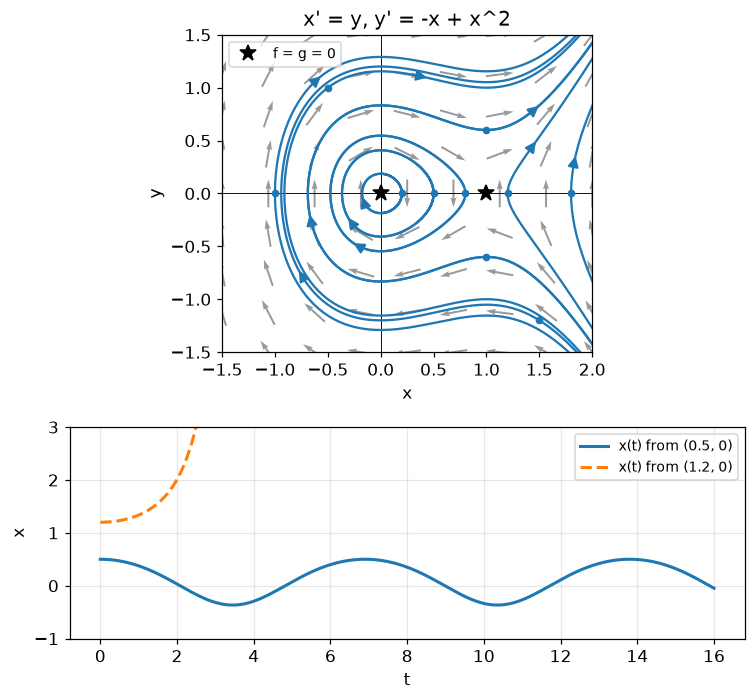

at (0, 0): (f, g) = (0, 0)
at (1, 0): (f, g) = (0, 0)


In [8]:
def example_811(x, y):
    return y, -x + x ** 2               # Lebl, Example 8.1.1: x' = y, y' = -x + x^2


WINDOW_811 = ((-1.5, 2.0), (-1.5, 1.5))
STARTS_811 = [(0.2, 0.0), (0.5, 0.0), (0.8, 0.0), (1.2, 0.0), (-1.0, 0.0), (-0.5, 1.0), (1.0, 0.6),
              (1.0, -0.6), (1.5, -1.2), (1.8, 0.0)]
T_811 = 8.0
TIME_STARTS = ((0.5, 0.0), (1.2, 0.0))
STACKED_FIGURE = (7.0, 6.5)             # a phase plane above, a graph in time below
TIME_WINDOW_811 = (-1.0, 3.0)           # the x axis of the graph in time; room for the legend
EQUILIBRIA_811 = ((0.0, 0.0), (1.0, 0.0))
fig, (picture, timeline) = plt.subplots(2, 1, figsize=STACKED_FIGURE, gridspec_kw={"height_ratios": [1.5, 1]})
plane_axes(picture, "x' = y, y' = -x + x^2")
# *WINDOW_811 spreads ((x_lo, x_hi), (y_lo, y_hi)) into x_range, y_range; the last number: arrows per side
ol.direction_field(picture, example_811, *WINDOW_811, FIELD_ARROWS)                # step 2
ol.phase_portrait(picture, example_811, STARTS_811, (0.0, T_811), *WINDOW_811)     # steps 3 and 4
picture.plot(*np.transpose(EQUILIBRIA_811), "*",   # np.transpose: the x values, then the y values
             color="black", markersize=STAR_SIZE, label="f = g = 0")
picture.legend(loc="upper left")
# paths[i, k] is the point (x, y) of start number k at times[i]; paths[:, k, 0] is x(t) of start k
# window=...: a path that goes far outside becomes NaN ("not a number", not drawn) from there on
times, paths = ol.trajectories(example_811, TIME_STARTS, (0.0, 2 * T_811), window=WINDOW_811)
for k, style in enumerate(("-", "--")):
    start = TIME_STARTS[k]
    timeline.plot(times, paths[:, k, 0], style, linewidth=2, label=f"x(t) from ({start[0]:g}, {start[1]:g})")
timeline.set_xlabel("t")
timeline.set_ylabel("x")
timeline.set_ylim(*TIME_WINDOW_811)
timeline.legend(loc="upper right")
plt.tight_layout()
plt.show()
for point in ((0, 0), (1, 0)):
    print(f"at {point}: (f, g) = {example_811(*point)}")

*The plot shows* Lebl's Figure 8.1.2; below, $x(t)$ from $(0.5, 0)$ (solid) swings between 0.5 and
about $-0.37$; from $(1.2, 0)$ (dashed) it grows and leaves the window.

(Answer: at the stars $(0, 0)$, which the curves go around, and $(1, 0)$, which they approach and leave;
Section 5 explains them.)

## 5. Equilibria and the Jacobian

*Lebl, Examples 8.1.1-8.1.2, by hand.* $f = y = 0$ and $g = -x + x^2 = x(x - 1) = 0$: the equilibria are
$(0, 0)$ and $(1, 0)$. The partial derivatives: $f_x = 0$, $f_y = 1$, $g_x = -1 + 2x$, $g_y = 0$, so

$$ J = \begin{pmatrix} 0 & 1 \\ -1 + 2x & 0 \end{pmatrix};\qquad
   \text{at } (1, 0):\ \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix},\qquad
   \text{at } (0, 0):\ \begin{pmatrix} 0 & 1 \\ -1 & 0 \end{pmatrix} . $$

At $(1, 0)$: $\operatorname{tr} J = 0$, $\det J = -1 < 0$: a saddle, eigenvalues $\pm 1$, eigenvectors
$(1, 1)$ for 1 and $(1, -1)$ for $-1$ (shortcut $(1, \lambda)$). At $(0, 0)$: $\det J = 1$,
$\operatorname{tr} J = 0$: eigenvalues $\pm i$, a center of the linearization (Section 6). The code checks
$J$ with SymPy and with `ol.jacobian` (for each variable, the slope between two points on each side, at
$10^{-5}$ times the size of the coordinate, at least $10^{-5}$).

SymPy: J = [[0, 1], [2*x - 1, 0]]
at (0, 0): ol.jacobian [[0.0, 1.0], [-1.0, 0.0]], largest difference 0e+00
at (1, 0): ol.jacobian [[0.0, 1.0], [1.0, 0.0]], largest difference 1e-12
at (1, 0): saddle (unstable): tr 0, det -1, eigenvalues -1 and 1
Example 8.2.1 at (0, 0): saddle (unstable): tr 0, det -1, eigenvalues -1 and 1
Example 8.2.1 at (1, -1): sink (asymptotically stable): tr -4, det 3, eigenvalues -3 and -1


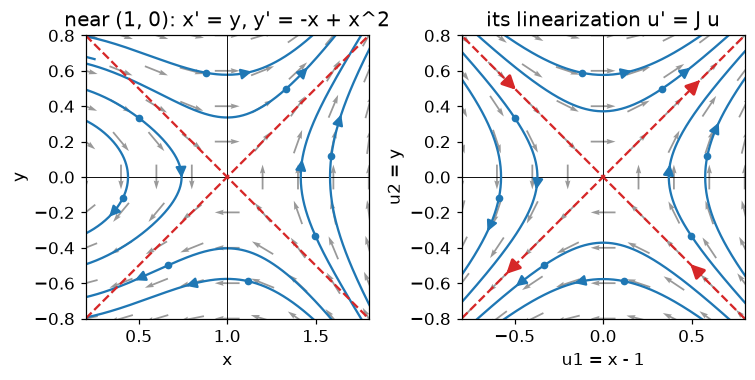

In [9]:
x, y = sp.symbols("x y", real=True)
J_811 = sp.Matrix([y, -x + x ** 2]).jacobian([x, y])     # the 2 x 2 matrix of the partial derivatives
print("SymPy: J =", J_811.tolist())
assert J_811 == sp.Matrix([[0, 1], [-1 + 2 * x, 0]])                                 # the values of the book
AGREEMENT = 1e-9                                        # ol.jacobian against SymPy
for point in ((0, 0), (1, 0)):
    numeric = ol.jacobian(example_811, point)
    exact = np.array(J_811.subs({x: point[0], y: point[1]}), dtype=float)
    print(f"at {point}: ol.jacobian {(numeric.round(9) + 0.0).tolist()}, largest difference "
          f"{np.max(np.abs(numeric - exact)):.0e}")
    assert np.allclose(numeric, exact, atol=AGREEMENT)
# it gives .jacobian (J at the point), .linear (classify_linear_2d of J), .stability and .reason
saddle_811 = ol.classify_equilibrium_2d(example_811, (1, 0))
report("at (1, 0)", saddle_811.linear)

# Lebl, Example 8.2.1: x' = -y - x^2, y' = -x + y^2, in two lines
for point in ((0, 0), (1, -1)):
    report(f"Example 8.2.1 at {point}", ol.classify_equilibrium_2d(lambda x, y: (-y - x ** 2, -x + y ** 2),
                                                                     point).linear)

# drawing code: you can skip reading it
NEAR = 0.8                              # the half-width of both windows, around the equilibrium
NEAR_RADIUS = 0.6                       # the starts lie on a circle of this radius
N_NEAR = 8                              # starts around the saddle
QUARTER_STEP = np.pi / (2 * N_NEAR)    # turn the circle of starts: off the axes, no two on one curve
NEAR_ANGLES = np.linspace(0.0, 2 * np.pi, N_NEAR, endpoint=False) + QUARTER_STEP
STARTS_NEAR = [(NEAR_RADIUS * np.cos(angle), NEAR_RADIUS * np.sin(angle)) for angle in NEAR_ANGLES]
SLOPES_AT_1 = (1.0, -1.0)               # the eigenvector directions (1, 1) and (1, -1) at (1, 0)
T_NEAR = 4.0                            # near the saddle the motion is slow: follow the curves longer
fig, (nonlinear, linearized) = plt.subplots(1, 2, figsize=PAIR_FIGURE)
window_x, window_u = ((1 - NEAR, 1 + NEAR), (-NEAR, NEAR)), ((-NEAR, NEAR), (-NEAR, NEAR))
starts_x = [(1 + u1, u2) for u1, u2 in STARTS_NEAR]    # the same starts, around (1, 0)
plane_axes(nonlinear, "near (1, 0): x' = y, y' = -x + x^2")
ol.direction_field(nonlinear, example_811, *window_x, FEW_ARROWS)
ol.phase_portrait(nonlinear, example_811, starts_x, (0.0, T_NEAR), *window_x)
nonlinear.axvline(1.0, color="black", linewidth=0.6)
for slope in SLOPES_AT_1:                              # the same dashed directions, through (1, 0)
    nonlinear.plot([1 - NEAR, 1 + NEAR], [-slope * NEAR, slope * NEAR], "--", color="C3", linewidth=1.5)
J_at_1 = saddle_811.jacobian
plane_axes(linearized, "its linearization u' = J u", "u1 = x - 1", "u2 = y")
ol.direction_field(linearized, linear_field(J_at_1), *window_u, FEW_ARROWS)
ol.phase_portrait(linearized, linear_field(J_at_1), STARTS_NEAR, (0.0, T_NEAR), *window_u)
draw_eigenlines(linearized, J_at_1, window_u[0])
plt.tight_layout()
plt.show()

*The plot shows* the true system near $(1, 0)$ (left) beside $\vec{u}\,' = J\vec{u}$ (right, Lebl's Figure
8.1.3): two saddles; the same dashed lines show where the curves come in and go out; farther away the
left curves bend. The printout also classifies Lebl's Example 8.2.1.

## 6. When the linearization tells the truth

(The theory exercise of Session 20.) An equilibrium with $\det J \ne 0$ is **almost linear** (Lebl
8.2.1: no other equilibrium is near it). Lebl's Table 8.2.1 is Section 1's table for $J$ without the
center, with the stability of Section 3.

**The rule.** If no eigenvalue of $J$ has real part 0 ($\det J \ne 0$ and $J$ not a center), the
equilibrium has the stability of $\vec{u}\,' = J\vec{u}$, and near it the same picture: a saddle, a node
or a spiral (if $J$ has one eigenvalue twice, the curves may also turn slowly around the point; $f$, $g$
with continuous partial derivatives, as in every example here). Lebl states it without proof. If $J$ is
a **center**, the small nonlinear terms decide; if $\det J = 0$, the linearization does not decide the
picture either (not almost linear). The evidence: two systems with **the same**
$J = \begin{pmatrix} 0 & 1 \\ -1 & 0 \end{pmatrix}$ at the origin. A quantity that does not change along
any solution is **conserved** (notebook 12's $F(x, y) = C$): each solution stays on one level curve.
* *Example 8.1.1*: the energy $E(x, y) = \tfrac12y^2 + \tfrac12x^2 - \tfrac13x^3$ ($x'' = -x + x^2$
  times $x'$, integrated; Lebl 8.2.4) has, by the chain rule,
  $E' = yy' + (x - x^2)x' = y(-x + x^2) + (x - x^2)y = 0$, so near the origin, where
  $E \approx \tfrac12(x^2 + y^2)$, the curves $E = $ constant are closed: a true **center** (stable). The
  curve through the saddle $(1, 0)$ (Lebl's text prints $(0, 1)$ here and in Section 8.2.1), $E = 1/6$,
  separates the closed curves from the others.
* *Example 8.2.3*: $x' = y$, $y' = -x + y^3$: $(x^2 + y^2)' = 2xy + 2y(-x + y^3) = 2y^4$ (Lebl's
  Exercise 8.2.5): the distance from the origin grows ($2y^4 > 0$ except where the curve crosses
  $y = 0$): a **spiral source** (unstable).

Example 8.1.1: dE/dt = 0
Example 8.2.3: d(x^2 + y^2)/dt = 2*y(t)**4
E at the saddle (1, 0): 1/6
Example 8.1.1 at (0, 0): inconclusive, because the linearization is a center: the nonlinear terms decide (Lebl, Section 8.2.3)
Example 8.2.3 at (0, 0): inconclusive, because the linearization is a center: the nonlinear terms decide (Lebl, Section 8.2.3)


Example 8.1.1: from distance 0.2, the distance stays near 0.2


Example 8.2.3: from distance 0.2, the distance reaches 2 at t = 33.0


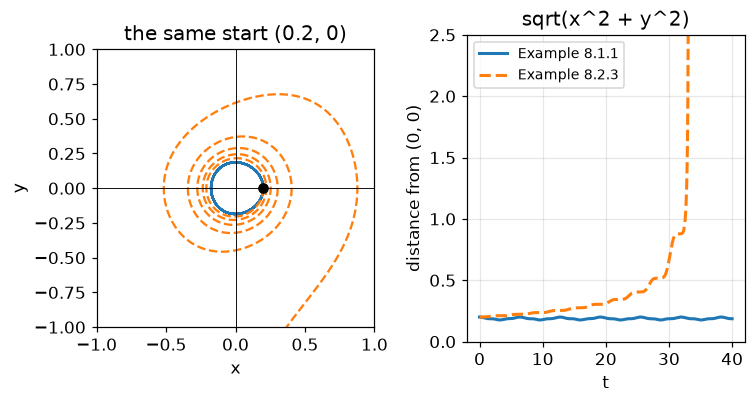

In [10]:
def example_823(x, y):
    return y, -x + y ** 3               # Lebl, Example 8.2.3


t = sp.symbols("t")
X, Y = sp.Function("x")(t), sp.Function("y")(t)
along_811 = {X.diff(t): Y, Y.diff(t): -X + X ** 2}      # what the equations say x' and y' are
energy = Y ** 2 / 2 + X ** 2 / 2 - X ** 3 / 3
print("Example 8.1.1: dE/dt =", sp.simplify(energy.diff(t).subs(along_811)))
assert sp.simplify(energy.diff(t).subs(along_811)) == 0
along_823 = {X.diff(t): Y, Y.diff(t): -X + Y ** 3}
print("Example 8.2.3: d(x^2 + y^2)/dt =", sp.factor((X ** 2 + Y ** 2).diff(t).subs(along_823)))
print("E at the saddle (1, 0):", energy.subs({X: 1, Y: 0}))
for name, field in (("Example 8.1.1", example_811), ("Example 8.2.3", example_823)):
    found = ol.classify_equilibrium_2d(field, (0, 0))
    print(f"{name} at (0, 0): {found.stability}, because {found.reason}")

START_SAME = (0.2, 0.0)
T_SAME = 40.0
SAME_STEPS = 4000
DISTANCE = 2.0                          # how far from the origin the spiral is followed
FOLLOWED = ((-3.0, 3.0), (-3.0, 3.0))   # the paths are computed in this window
SHOWN = (-1.0, 1.0)                     # and drawn in this one, in x and in y
DISTANCE_WINDOW = (0.0, 2.5)
fig, (plane, distances) = plt.subplots(1, 2, figsize=PAIR_FIGURE)
SAME_J = (("Example 8.1.1", example_811, "-"), ("Example 8.2.3", example_823, "--"))
for name, field, style in SAME_J:
    times, paths = ol.trajectories(field, START_SAME, (0.0, T_SAME), SAME_STEPS, window=FOLLOWED)
    plane.plot(paths[:, 0, 0], paths[:, 0, 1], style, linewidth=1.5, label=name)
    distance = np.hypot(paths[:, 0, 0], paths[:, 0, 1])
    distances.plot(times, distance, style, linewidth=2, label=name)
    far = np.flatnonzero(distance >= DISTANCE)   # the indices where the distance is at least 2 (maybe none)
    # "A if condition else B": A when the condition holds, B otherwise; far[0] is the first index
    reached = f"reaches {DISTANCE:g} at t = {times[far[0]]:.1f}" if far.size else "stays near 0.2"
    print(f"{name}: from distance {distance[0]:g}, the distance {reached}")
plane.plot(*START_SAME, "o", color="black")
plane.set_xlim(*SHOWN)
plane.set_ylim(*SHOWN)
plane_axes(plane, "the same start (0.2, 0)")
distances.set_ylim(*DISTANCE_WINDOW)
distances.set_xlabel("t")
distances.set_ylabel("distance from (0, 0)")
distances.set_title("sqrt(x^2 + y^2)")
distances.legend(loc="upper left")
plt.tight_layout()
plt.show()

*The plot shows*, from $(0.2, 0)$, Example 8.1.1 (solid) on one closed curve, near distance 0.2;
Example 8.2.3 (dashed) turning clockwise and slowly away (Lebl's Figure 8.2.3), to distance 2 at
$t = 33.0$.

## 7. Two models: the pendulum and the hares and foxes

(The practical exercise of Session 20.)

**Conventions (pendulum).** $\theta(t)$: the angle in radians between the rod and the downward vertical,
0 when the pendulum hangs at rest, **positive counterclockwise** in the drawing; $\theta'$ in rad/s,
positive counterclockwise; $t$ in seconds, $t = 0$ when the motion starts; the length $\ell = 9.81$ m, so
$g/\ell = 1$ /s$^2$ (Lebl takes $g/L = 1$ "for simplicity": the length is this notebook's). Here $g$ is
gravity, not a right-hand side. Lebl writes $\omega$ for $\theta'$ and $L$ for the length.

*Lebl, Section 8.3.1:* $\theta'' + (g/\ell)\sin\theta = 0$ (not linear, notebook 09), as the system
$x' = y$, $y' = -(g/\ell)\sin x$ with $x = \theta$, $y = \theta'$, drawn in the plane $(\theta, \theta')$.
Equilibria: $\theta' = 0$ and $\sin\theta = 0$: $(k\pi, 0)$, $k$ an integer.
$J = \begin{pmatrix} 0 & 1 \\ -(g/\ell)\cos\theta & 0 \end{pmatrix}$:
* at $(0, 0)$: eigenvalues $\pm i$ per second, a center of the linearization: inconclusive. But the
  energy $E(\theta, \theta') = \tfrac12\theta'^2 - (g/\ell)\cos\theta$ is conserved:
  $E' = \theta'(\theta'' + (g/\ell)\sin\theta) = 0$, so the curves close: a true center, the swings;
* at $(\pi, 0)$ ($\cos\pi = -1$): eigenvalues $\pm 1$ per second, a saddle: the pendulum upside down.

The curves run clockwise: above the axis $\theta' > 0$, so $\theta$ grows (they move right).

(theta, theta') = (-pi, 0): saddle, eigenvalues -1 and 1 per second -> unstable
(theta, theta') = (0, 0): center, eigenvalues +- 1i per second -> inconclusive
(theta, theta') = (pi, 0): saddle, eigenvalues -1 and 1 per second -> unstable
(theta, theta') = (2 pi, 0): center, eigenvalues +- 1i per second -> inconclusive


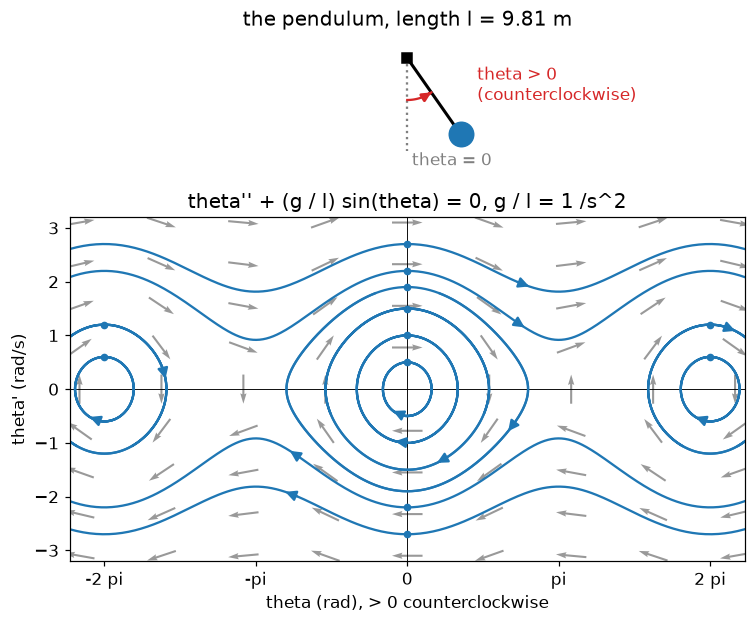

In [11]:
G_OVER_L = 1.0                          # 1/s^2: g / l with l = 9.81 m


def pendulum(theta, dtheta):
    # (theta', theta''): theta in rad, positive counterclockwise; dtheta = theta' in rad/s
    return dtheta, -G_OVER_L * np.sin(theta)


for k, name in zip(range(-1, 3), ("-pi", "0", "pi", "2 pi")):          # (k pi, 0) for k = -1, 0, 1, 2
    found = ol.classify_equilibrium_2d(pendulum, (k * np.pi, 0.0))
    print(f"(theta, theta') = ({name}, 0): {found.linear.kind}, eigenvalues "
          f"{describe(found.linear.eigenvalues)} per second -> {found.stability}")
# E' = theta' theta'' + (g/l) sin(theta) theta' = theta' (theta'' + (g/l) sin(theta)) = 0 along a solution
theta = sp.Function("theta")(t)
energy_pendulum = theta.diff(t) ** 2 / 2 - G_OVER_L * sp.cos(theta)
assert sp.simplify(energy_pendulum.diff(t).subs(theta.diff(t, 2), -G_OVER_L * sp.sin(theta))) == 0

# drawing code: you can skip reading it
PENDULUM_FIGURE = (7.0, 5.8)            # the drawing above, the phase plane below
DRAWING_SHARE = (0.65, 1.6)             # heights of the drawing and of the phase plane
BOB_SIZE = 16
ROD = 1.0                               # length of the rod in the drawing
DRAWN_ANGLE = np.radians(35)            # the pendulum is drawn at this angle
ARC = 0.45                              # radius of the arc that marks theta
ARC_POINTS = 30
ARC_ARROW = 0.8                         # the arrowhead covers the last fifth of the arc
ANGLE_LABEL = (0.75, -0.45)             # where "theta > 0" is written, right of the rod
REST_LABEL = (0.05, -1.15)              # where "theta = 0" is written, under the vertical
DRAWING_WINDOW = (-1.6, 1.6, -1.25, 0.25)
WINDOW_PENDULUM = ((-7.0, 7.0), (-3.2, 3.2))     # theta (rad), theta' (rad/s)
SPEEDS_AT_0 = (0.5, 1.0, 1.5, 1.9, 2.2, 2.7, -2.2, -2.7)     # rad/s: theta'(0) of the starts at theta = 0
SPEEDS_AT_2PI = (0.6, 1.2)                                  # the same around theta = 2 pi and -2 pi
STARTS_PENDULUM = ([(0.0, speed) for speed in SPEEDS_AT_0] + [(2 * np.pi, speed) for speed in SPEEDS_AT_2PI]
                   + [(-2 * np.pi, speed) for speed in SPEEDS_AT_2PI])
T_PENDULUM = 10.0                       # s, each way
fig, (drawing, picture) = plt.subplots(2, 1, figsize=PENDULUM_FIGURE,
                                      gridspec_kw={"height_ratios": list(DRAWING_SHARE)})
bob = ROD * np.array([np.sin(DRAWN_ANGLE), -np.cos(DRAWN_ANGLE)])
drawing.plot([0.0, 0.0], [0.0, -ROD], ":", color="gray")                        # the downward vertical
drawing.plot([0.0, bob[0]], [0.0, bob[1]], "-", color="black", linewidth=2)
drawing.plot(*bob, "o", color="C0", markersize=BOB_SIZE)
drawing.plot(0.0, 0.0, "s", color="black")
arc = np.linspace(0.0, DRAWN_ANGLE, ARC_POINTS)
drawing.plot(ARC * np.sin(arc), -ARC * np.cos(arc), color="C3")
drawing.annotate("", xy=(ARC * np.sin(DRAWN_ANGLE), -ARC * np.cos(DRAWN_ANGLE)),
                 xytext=(ARC * np.sin(ARC_ARROW * DRAWN_ANGLE), -ARC * np.cos(ARC_ARROW * DRAWN_ANGLE)),
                 arrowprops={"arrowstyle": "-|>", "color": "C3", "lw": 2})
drawing.text(*ANGLE_LABEL, "theta > 0\n(counterclockwise)", color="C3", ha="left")
drawing.text(*REST_LABEL, "theta = 0", color="gray", ha="left")
drawing.axis(DRAWING_WINDOW)
drawing.set_aspect("equal")
drawing.set_axis_off()
drawing.set_title("the pendulum, length l = 9.81 m")
plane_axes(picture, "theta'' + (g / l) sin(theta) = 0, g / l = 1 /s^2", "theta (rad), > 0 counterclockwise",
           "theta' (rad/s)", equal=False)
ARROWS_PENDULUM = ((-6.8, 6.8), (-3.1, 3.1))     # the arrows lie inside the window: none cut in half
ol.direction_field(picture, pendulum, *ARROWS_PENDULUM, FIELD_ARROWS)
ol.phase_portrait(picture, pendulum, STARTS_PENDULUM, (0.0, T_PENDULUM), *WINDOW_PENDULUM)
picture.set_xticks(np.pi * np.arange(-2, 3))
picture.set_xticklabels(["-2 pi", "-pi", "0", "pi", "2 pi"])
plt.tight_layout()
plt.show()

*The plot shows* the pendulum at $\theta > 0$ and Lebl's Figure 8.3.2: swings (closed curves) around
$(0, 0)$ and $(\pm 2\pi, 0)$, saddles at $(\pm\pi, 0)$, and turns over the top (wavy curves); the curve
through the saddles, between the starts 1.9 and 2.2 rad/s, separates them (Exercise 2(d)).

**Conventions (hares and foxes).** $x(t)$ the number of hares, $y(t)$ the number of foxes (Lebl's
(8.3.1)), both $\ge 0$ (only that quarter is drawn); $x' > 0$ means the hares are increasing; $t$ in
"time units" (Lebl gives none). Lebl's four rates, not the coefficients of notebook 06: $a = 0.4$ and
$d = 0.3$ per time unit, $b = 0.01$ per fox per time unit, $c = 0.003$ per hare per time unit.

*Lebl, Section 8.3.2:* $x' = (a - by)x$, $y' = (cx - d)y$: the hares grow at the rate $a$ and are eaten
($bxy$); the foxes are fed ($cxy$) and die at the rate $d$. Equilibria: $x = 0$ with $y = 0$, or
$y = a/b$ with $x = d/c$: $(0, 0)$ and $(d/c, a/b) = (100, 40)$.
$J = \begin{pmatrix} a - by & -bx \\ cy & cx - d \end{pmatrix}$:
* at $(0, 0)$, $\begin{pmatrix} a & 0 \\ 0 & -d \end{pmatrix}$: eigenvalues 0.4 and $-0.3$, a saddle;
* at $(100, 40)$, $\begin{pmatrix} 0 & -bd/c \\ ac/b & 0 \end{pmatrix}$ ($\lambda^2 + ad = 0$):
  eigenvalues $\pm i\sqrt{ad} = \pm 0.346i$, a center of the linearization: inconclusive.

Lebl's **constant of motion** $C(x, y) = y^ax^de^{-cx - by}$ is conserved, $C' = 0$ (printed below), and
$(d/c, a/b)$ is its maximum (Lebl; his Exercise 8.3.3), so the curves $C = $ constant around it are
closed, like the level curves around a hilltop: the populations repeat. Small swings repeat every
$2\pi/\sqrt{ad} = 18.1$ time units (period $2\pi/\beta$, as in notebook 17); Lebl's start, farther out,
takes 19.35.

(0, 0): saddle, eigenvalues -0.3 and 0.4 per time unit -> unstable
(100, 40): center, eigenvalues +- 0.346i per time unit -> inconclusive
small swings repeat every 2 pi / sqrt(ad) = 18.1 time units
dC/dt along a solution: 0
C along the rk4 solution: largest relative change 9e-10
hares between 32.4 and 227.1, foxes between 15.4 and 82.5
back at the start after 19.35 time units


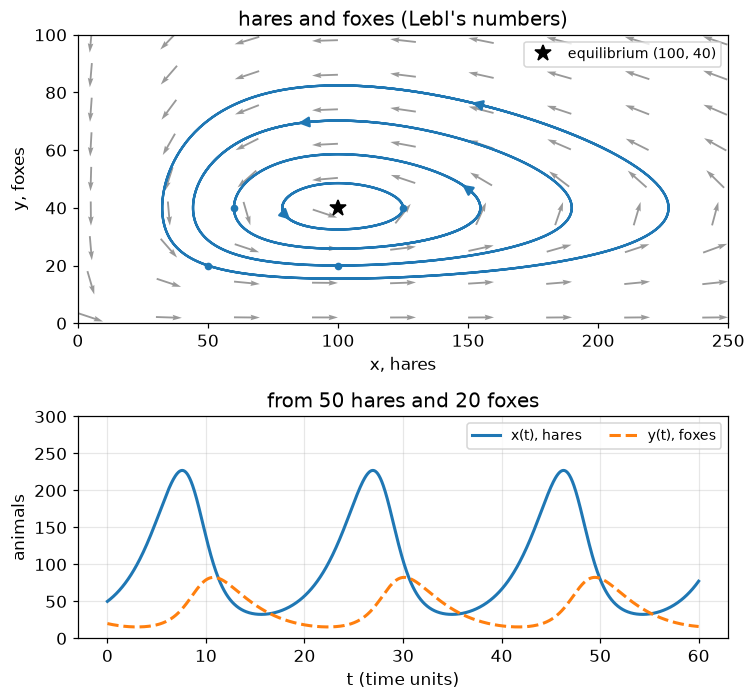

In [12]:
LV_A, LV_B, LV_C, LV_D = 0.4, 0.01, 0.003, 0.3          # Lebl's a, b, c, d (per time unit, see above)
LV_START = (50.0, 20.0)                                # Lebl: 50 hares and 20 foxes
T_LV = 60.0                                            # time units: more than two periods
LV_STEPS = 1200


def lotka_volterra(x, y):
    # (x', y') for x hares and y foxes
    return (LV_A - LV_B * y) * x, (LV_C * x - LV_D) * y


for point in ((0.0, 0.0), (LV_D / LV_C, LV_A / LV_B)):
    found = ol.classify_equilibrium_2d(lotka_volterra, point)
    print(f"({point[0]:g}, {point[1]:g}): {found.linear.kind}, eigenvalues "
          f"{describe(found.linear.eigenvalues)} per time unit -> {found.stability}")
print(f"small swings repeat every 2 pi / sqrt(ad) = {2 * np.pi / np.sqrt(LV_A * LV_D):.1f} time units")

rate_a, rate_b, rate_c, rate_d = sp.symbols("a b c d", positive=True)       # Lebl's letters, for SymPy
constant = Y ** rate_a * X ** rate_d * sp.exp(-rate_c * X - rate_b * Y)
along_lv = {X.diff(t): (rate_a - rate_b * Y) * X, Y.diff(t): (rate_c * X - rate_d) * Y}
print("dC/dt along a solution:", sp.simplify(constant.diff(t).subs(along_lv)))       # Lebl, (8.3.3)
assert sp.simplify(constant.diff(t).subs(along_lv)) == 0

times, paths = ol.trajectories(lotka_volterra, LV_START, (0.0, T_LV), LV_STEPS)
hares, foxes = paths[:, 0, 0], paths[:, 0, 1]
values = foxes ** LV_A * hares ** LV_D * np.exp(-LV_C * hares - LV_B * foxes)      # C along the path
print(f"C along the rk4 solution: largest relative change {np.max(np.abs(values / values[0] - 1)):.0e}")
print(f"hares between {hares.min():.1f} and {hares.max():.1f}, foxes between {foxes.min():.1f} and "
      f"{foxes.max():.1f}")
# the start had foxes going down: it is back when they cross 20 downwards again (after t = 0).
# down: the indices i where foxes[i] > 20 and foxes[i + 1] <= 20 (& means "and" for arrays):
# the fox curve crosses 20 going down there
down = np.flatnonzero((foxes[1:-1] > LV_START[1]) & (foxes[2:] <= LV_START[1])) + 1
before, after = down[0], down[0] + 1
# the straight line between the two points crosses 20 at this time (as in Exercise 4(v))
period = times[before] + (foxes[before] - LV_START[1]) / (foxes[before] - foxes[after]) * (times[after]
                                                                                           - times[before])
print(f"back at the start after {period:.2f} time units")

# drawing code: you can skip reading it
WINDOW_LV = ((0.0, 250.0), (0.0, 100.0))               # hares, foxes
STARTS_LV = [LV_START, (100.0, 20.0), (60.0, 40.0), (125.0, 40.0)]
ANIMALS_WINDOW = (0.0, 300.0)                          # the axis of the graph in time; room for the legend
fig, (picture, timeline) = plt.subplots(2, 1, figsize=STACKED_FIGURE, gridspec_kw={"height_ratios": [1.3, 1]})
plane_axes(picture, "hares and foxes (Lebl's numbers)", "x, hares", "y, foxes", equal=False)
ARROWS_LV = ((5.0, 245.0), (2.0, 98.0))                # the arrows lie inside the window
ol.direction_field(picture, lotka_volterra, *ARROWS_LV, FIELD_ARROWS)
ol.phase_portrait(picture, lotka_volterra, STARTS_LV, (0.0, T_LV / 2), *WINDOW_LV)
picture.plot(LV_D / LV_C, LV_A / LV_B, "*", color="black", markersize=STAR_SIZE,
             label="equilibrium (100, 40)")
picture.legend(loc="upper right")
timeline.plot(times, hares, "-", linewidth=2, label="x(t), hares")
timeline.plot(times, foxes, "--", linewidth=2, label="y(t), foxes")
timeline.set_xlabel("t (time units)")
timeline.set_ylabel("animals")
timeline.set_ylim(*ANIMALS_WINDOW)
timeline.legend(loc="upper right", ncol=2)
timeline.set_title("from 50 hares and 20 foxes")
plt.tight_layout()
plt.show()

*The plot shows* Lebl's Figure 8.3.5: closed curves around $(100, 40)$, run counterclockwise; below, the
hares (solid) peak, then the foxes (dashed).

**Slider: more foxes.** From $x(0) = 50$ hares and $y(0)$ foxes (Lebl's remark).
Before moving it: if we bring many more foxes into the forest (up to 200), do the hares do better, or
worse?

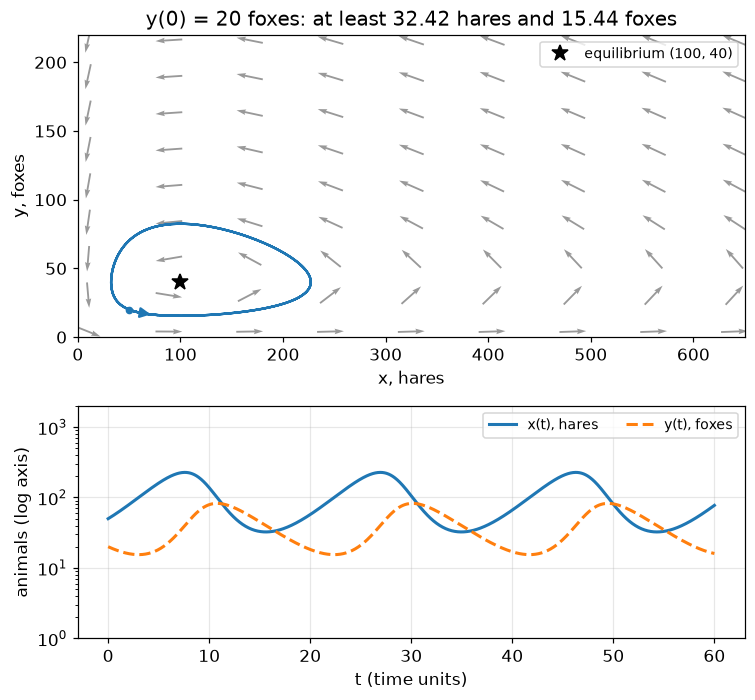

In [13]:
DEFAULT_FOXES = 20.0
FOXES_RANGE = (10.0, 200.0, 10.0)                       # minimum, maximum, step
WINDOW_FOXES = ((0.0, 650.0), (0.0, 220.0))             # holds every curve of the slider
ARROWS_FOXES = ((10.0, 640.0), (4.0, 216.0))            # the arrows lie inside the window
START_HARES = 50.0
LOG_WINDOW = (1.0, 2000.0)                              # animals, on the log axis; room for the legend


def plot_foxes(foxes=DEFAULT_FOXES):
    # Lebl's hares and foxes from 50 hares and the chosen number of foxes
    times, paths = ol.trajectories(lotka_volterra, (START_HARES, foxes), (0.0, T_LV), LV_STEPS)
    hares, fox_numbers = paths[:, 0, 0], paths[:, 0, 1]
    fig, (picture, timeline) = plt.subplots(2, 1, figsize=STACKED_FIGURE,
                                            gridspec_kw={"height_ratios": [1.3, 1]})
    plane_axes(picture, f"y(0) = {foxes:.0f} foxes: at least {hares.min():.2f} hares and "
               f"{fox_numbers.min():.2f} foxes", "x, hares", "y, foxes", equal=False)
    ol.direction_field(picture, lotka_volterra, *ARROWS_FOXES, FIELD_ARROWS)
    ol.phase_portrait(picture, lotka_volterra, [(START_HARES, foxes)], (0.0, T_LV), *WINDOW_FOXES,
                      n_steps=LV_STEPS, both_ways=False)
    picture.plot(LV_D / LV_C, LV_A / LV_B, "*", color="black", markersize=STAR_SIZE,
                 label="equilibrium (100, 40)")
    picture.legend(loc="upper right")
    timeline.semilogy(times, hares, "-", linewidth=2, label="x(t), hares")
    timeline.semilogy(times, fox_numbers, "--", linewidth=2, label="y(t), foxes")
    timeline.set_ylim(*LOG_WINDOW)
    timeline.set_xlabel("t (time units)")
    timeline.set_ylabel("animals (log axis)")
    timeline.legend(loc="upper right", ncol=2)
    plt.tight_layout()
    plt.show()


plot_foxes()

In [14]:
interact(plot_foxes, foxes=FloatSlider(value=DEFAULT_FOXES, min=FOXES_RANGE[0], max=FOXES_RANGE[1],
                                       step=FOXES_RANGE[2], description="foxes", continuous_update=False));

interactive(children=(FloatSlider(value=20.0, continuous_update=False, description='foxes', max=200.0, min=10....

*The static plot shows* Lebl's start again; below, on a logarithmic axis (each step up is 10 times more,
notebook 01), the populations rise and fall.

(Answer: it depends on how many. Every curve is closed, so the populations always come back, but the
larger the closed curve through the start, the deeper the fall. Up to 40 foxes the curve shrinks (the
hares are lowest where $x' = 0$, on the line $y = a/b = 40$, and from 50 hares and 40 foxes the start is
that point: the hares never fall below 50); beyond about 70 foxes it is larger than Lebl's, and with 200
foxes the hares fall to about one (Lebl: "slightly more than 1 hare"; Exercise 4(i) measures it): in a
real forest, extinction (the model allows 0.1 fox, Lebl warns).)

## 8. Exercises

Final answers are at the end; try first. After Session 19: Exercises 1(a), 1(b), 2(a), 4(ii), 4(iii);
after Session 20: the rest. A word answer is typed in quotes, as `my_kind = "center"`; the words are
source, sink, saddle, center, spiral source, spiral sink (Lebl's "unstable node", "stable node" and the
spelling "centre" are accepted), and for stability: asymptotically stable, stable, unstable.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

* (a) *(Lebl, Exercise 3.5.7)* $A$ is a $2 \times 2$ matrix with eigenvalues $2 \pm i$. What is the picture
  of $\vec{x}\,' = A\vec{x}$?
* (b) *(From Lebl, Exercise 3.5.4)* True or False: a diagonal matrix
  $\begin{pmatrix} a_{11} & 0 \\ 0 & a_{22} \end{pmatrix}$ with $a_{11}, a_{22} \ne 0$ can give a spiral.
* (c) *(From Lebl, Exercise 8.2.7)* If $g(x, y) > 1$ at every point, how many equilibria has
  $x' = f(x, y)$, $y' = g(x, y)$? (An equilibrium needs $f = g = 0$.)
* (d) *(From Lebl, Section 8.2.4)* True or False: a conservative equation $x'' + f(x) = 0$ can have an
  asymptotically stable equilibrium. (Here the unknown is $x(t)$ and $f$ is Lebl's, a function of $x$
  alone; *conservative*: no term in $x'$, no friction. First step: as a system $x' = y$, $y' = -f(x)$; the
  energy $E(x, y) = \tfrac12 y^2 + \int f(x)\,dx$ is conserved (Section 6). Can a solution that starts
  near the equilibrium, with another value of $E$, tend to it?)

In [15]:
my_kind_357 = None
my_diagonal_spiral = None       # True or False
my_number_of_equilibria = None
my_conservative_sink = None     # True or False
# ---- your answers go above this line; the lines below check them (nothing to change) ----

SPIRALS = (ol.KIND_SPIRAL_SOURCE, ol.KIND_SPIRAL_SINK, ol.KIND_CENTER)
SIGNS = (1.0, -1.0)
SAMPLE_GRID = np.linspace(-50.0, 50.0, 201)
SAMPLE_SLOPES = (-2.0, -0.5, 0.5, 2.0)                  # values of f'(x*) for Exercise 1(d)
DIAGONAL = (1.0, 3.0)                                   # sizes of a11 and a22 in Exercise 1(b)
kind_357 = ol.classify_linear_2d([[2, -1], [1, 2]]).kind
ol.check_choice("Exercise 1a", my_kind_357, kind_357, ol.PORTRAIT_WORDS, ol.KIND_SYNONYMS)
# a set {...} keeps each kind once; & is what two sets have in common
diagonal_kinds = {ol.classify_linear_2d([[s1 * DIAGONAL[0], 0.0], [0.0, s2 * DIAGONAL[1]]]).kind
                  for s1 in SIGNS for s2 in SIGNS}
ol.check("Exercise 1b", my_diagonal_spiral, bool(diagonal_kinds & set(SPIRALS)))
grid_x, grid_y = np.meshgrid(SAMPLE_GRID, SAMPLE_GRID)
sample_g = 2.0 + np.sin(grid_x * grid_y)                                   # a function with g > 1
ol.check("Exercise 1c", my_number_of_equilibria, np.count_nonzero(sample_g == 0))
conservative = [ol.classify_linear_2d([[0.0, 1.0], [-slope, 0.0]]).stability for slope in SAMPLE_SLOPES]
ol.check("Exercise 1d", my_conservative_sink, ol.STABILITY_ASYMPTOTIC in conservative);

Exercise 1a: no answer yet (replace None with your answer, a word in quotes)
Exercise 1b: no answer yet (replace None with your value)
Exercise 1c: no answer yet (replace None with your value)
Exercise 1d: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *From Lebl, Exercise 3.5.6 (d) and (e)* (no units). For (d) $x' = x + 3y$, $y' = -2x - 4y$ and
for (e) $x' = x - 4y$, $y' = -4x + y$: the trace and the determinant, as `[tr, det]`, and the picture
(Section 3, without computing an eigenvalue). (Row 1 of $A$: the coefficients of $x$ and $y$ in $x'$.)

**(b)** *From Lebl, Exercise 8.1.7 (c)* (no units). $x' = (x - 1)^2 + y$, $y' = x^2 + y$ has one
equilibrium: find it, as `(x, y)`; then $J$ there, as a list of rows `[[f_x, f_y], [g_x, g_y]]`, and the
picture. First step: subtract the two equations, $f - g = (x - 1)^2 - x^2 = 0$.

**(c)** *From Lebl, Exercise 8.2.8 (b)* (no units). $x' = y - y^2 - x$, $y' = -x$ has the equilibrium
$(0, 0)$ and one more: find it; then the picture and the stability of each. First step: $y' = 0$ gives
$x = 0$; put it into $x' = 0$.

**(d)** *From Lebl, Exercise 8.3.5 (b).* Convention: as in Section 7 ($\theta$ in rad from the downward
vertical, positive counterclockwise; $\theta'$ in rad/s; $g/\ell = 1$ /s$^2$). The pendulum starts at
$\theta(0) = 0$ with $\theta'(0) > 0$. What is the "crucial" speed $\theta'(0)$, in rad/s, above which it
goes over the top (and below which it swings back)? First step: the energy
$E(\theta, \theta') = \tfrac12\theta'^2 - (g/\ell)\cos\theta$ is conserved; at the top, $\theta = \pi$, the
speed $\theta'$ can be (almost) 0.

In [16]:
my_tr_det_d = None              # [tr, det]
my_kind_d = None
my_tr_det_e = None              # [tr, det]
my_kind_e = None
my_point_b = None               # (x, y)
my_jacobian_b = None            # [[f_x, f_y], [g_x, g_y]]
my_kind_b = None
my_other_point = None           # (x, y)
my_kind_origin = None
my_stability_origin = None
my_kind_other = None
my_stability_other = None
my_speed_over_the_top = None    # rad/s
# ---- your answers go above this line; the lines below check them (nothing to change) ----


def check_in_order(label, answer, expected):
    # ol.check_vector, with a hint when the right values come in the other order
    try:
        values = np.asarray(answer, dtype=float).ravel()        # .ravel(): a flat list, also from a number
        close = {"rtol": ol.CHECK_TOLERANCE, "atol": ol.CHECK_TOLERANCE}
        swapped = (values.size == len(expected) and not np.allclose(values, expected, **close)
                   and np.allclose(values[::-1], expected, **close))   # [::-1]: the list, last value first
    except (TypeError, ValueError):
        swapped = False
    if swapped:
        print(f"{label}: not yet (right values: write them in the order asked)")
        return False
    return ol.check_vector(label, answer, expected)


x, y = sp.symbols("x y", real=True)     # SymPy's x and y again (a cell above may have changed them)
EXERCISE_356 = {"d": [[1, 3], [-2, -4]], "e": [[1, -4], [-4, 1]]}         # Lebl, Exercise 3.5.6
for item, answers in (("d", (my_tr_det_d, my_kind_d)), ("e", (my_tr_det_e, my_kind_e))):
    phase = ol.classify_linear_2d(EXERCISE_356[item])
    check_in_order(f"Exercise 2a ({item}), tr and det", answers[0], [phase.trace, phase.determinant])
    ol.check_choice(f"Exercise 2a ({item}), picture", answers[1], phase.kind, ol.PORTRAIT_WORDS,
                    ol.KIND_SYNONYMS)

field_b = sp.Matrix([(x - 1) ** 2 + y, x ** 2 + y])                      # Lebl, Exercise 8.1.7 (c)
(point_b,) = [(s[x], s[y]) for s in sp.solve(list(field_b), [x, y], dict=True)]   # (one,) = a list of one
jacobian_b = np.array(field_b.jacobian([x, y]).subs({x: point_b[0], y: point_b[1]}), dtype=float)
check_in_order("Exercise 2b, equilibrium", my_point_b, [float(value) for value in point_b])
ol.check_vector("Exercise 2b, J", my_jacobian_b, jacobian_b)
ol.check_choice("Exercise 2b, picture", my_kind_b, ol.classify_linear_2d(jacobian_b).kind, ol.PORTRAIT_WORDS,
                ol.KIND_SYNONYMS)

field_c = (y - y ** 2 - x, -x)                                            # Lebl, Exercise 8.2.8 (b)
points_c = [(float(s[x]), float(s[y])) for s in sp.solve(field_c, [x, y], dict=True)]
(other_c,) = [point for point in points_c if point != (0.0, 0.0)]                 # the one that is not 0
check_in_order("Exercise 2c, the other equilibrium", my_other_point, other_c)
numeric_c = sp.lambdify((x, y), field_c, "numpy")
for name, point, kind, stability in (("(0, 0)", (0.0, 0.0), my_kind_origin, my_stability_origin),
                                     ("the other", other_c, my_kind_other, my_stability_other)):
    found = ol.classify_equilibrium_2d(numeric_c, point)
    ol.check_choice(f"Exercise 2c, {name}, picture", kind, found.linear.kind, ol.PORTRAIT_WORDS,
                    ol.KIND_SYNONYMS)
    ol.check_choice(f"Exercise 2c, {name}, stability", stability, found.stability, ol.STABILITY_WORDS)

TOP = np.pi                                                               # rad: the pendulum upside down
over_the_top = np.sqrt(2 * G_OVER_L * (np.cos(0.0) - np.cos(TOP)))        # from E at theta = 0 and at the top
ol.check("Exercise 2d", my_speed_over_the_top, over_the_top);

Exercise 2a (d), tr and det: no answer yet (replace None with your value)
Exercise 2a (d), picture: no answer yet (replace None with your answer, a word in quotes)
Exercise 2a (e), tr and det: no answer yet (replace None with your value)
Exercise 2a (e), picture: no answer yet (replace None with your answer, a word in quotes)
Exercise 2b, equilibrium: no answer yet (replace None with your value)
Exercise 2b, J: no answer yet (replace None with your value)
Exercise 2b, picture: no answer yet (replace None with your answer, a word in quotes)
Exercise 2c, the other equilibrium: no answer yet (replace None with your value)
Exercise 2c, (0, 0), picture: no answer yet (replace None with your answer, a word in quotes)
Exercise 2c, (0, 0), stability: no answer yet (replace None with your answer, a word in quotes)
Exercise 2c, the other, picture: no answer yet (replace None with your answer, a word in quotes)
Exercise 2c, the other, stability: no answer yet (replace None with your answer, a wor

### Exercise 3 - Fill in

(The practical exercise of Session 20, from *Lebl, Exercise 8.3.2*.) Convention: as for the hares and
foxes of Section 7 ($x$ hares, $y$ foxes, $t$ in time units). The hares now grow logistically (Lebl,
Section 1.6; the term $-\gamma x^2$ is the crowding of notebook 03's $kx(M - x)$):
$x' = (0.4 - 0.01y)x - \gamma x^2$, $y' = (0.003x - 0.3)y$, with $\gamma$ in 1/(hare and
time unit) ($\gamma$ is Lebl's letter here, not the phase of notebook 06). The drawing below shows the
direction field for $\gamma = 0.001$.

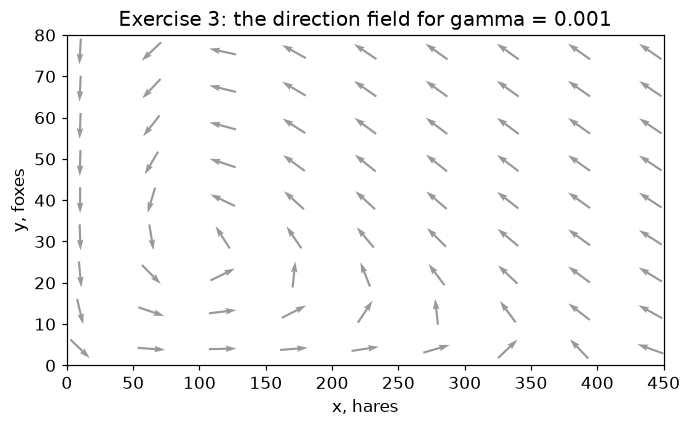

In [17]:
WINDOW_HARES = ((0.0, 450.0), (0.0, 80.0))             # hares, foxes
ARROWS_HARES = ((10.0, 440.0), (4.0, 76.0))            # the arrows lie inside the window: none half hidden
HARES_FIGURE = (7.0, 3.9)
GAMMA_SHOWN = 0.001                                    # 1/(hare and time unit)


def logistic_hares(x, y, gamma):
    # (x', y') of Lebl's Exercise 8.3.2
    return (LV_A - LV_B * y) * x - gamma * x ** 2, (LV_C * x - LV_D) * y


fig, ax = plt.subplots(figsize=HARES_FIGURE)
plane_axes(ax, f"Exercise 3: the direction field for gamma = {GAMMA_SHOWN:g}", "x, hares", "y, foxes",
           equal=False)
ol.direction_field(ax, lambda x, y: logistic_hares(x, y, GAMMA_SHOWN), *ARROWS_HARES, FIELD_ARROWS)
ax.set_xlim(*WINDOW_HARES[0])
ax.set_ylim(*WINDOW_HARES[1])
plt.show()

*The plot shows* the arrows $(x', y')$ for $\gamma = 0.001$: below 100 hares the foxes decrease (arrows
tilted down), above 100 hares they increase (tilted up); high up and far right the hares decrease
(pointing left); the arrows turn counterclockwise around a point near $(100, 30)$.

Complete `hares_jacobian(x, y, gamma)`, which returns the Jacobian matrix at $(x, y)$ as a list of rows
`[[f_x, f_y], [g_x, g_y]]`. First step: differentiate the right-hand side of $x'$ with respect to $x$,
holding $y$ fixed: the term $-\gamma x^2$ gives $-2\gamma x$; then the three other entries. The next cell
does not compare formulas: at five points and three values of $\gamma$ it compares your matrix with
`ol.jacobian` of the field. When it is right, it finds the equilibria with $x \ge 0$, $y \ge 0$ for
$\gamma = 0.001$ and $0.01$, classifies each with `ol.classify_linear_2d(hares_jacobian(...))` and draws
both phase portraits from Lebl's start, 50 hares and 20 foxes.

In [18]:
def hares_jacobian(x, y, gamma):
    return None                 # replace None with the formula

In [19]:
GAMMAS = (0.001, 0.005, 0.01)                          # 1/(hare and time unit)
CHECK_POINTS = ((50.0, 20.0), (400.0, 0.0), (100.0, 30.0), (10.0, 70.0), (0.0, 20.0))   # (hares, foxes)
JACOBIAN_TOLERANCE = 1e-6                              # relative: ol.jacobian is good to about 1e-9
ENTRY_NAMES = (("x' with respect to x", "x' with respect to y"),      # [row][column]
               ("y' with respect to x", "y' with respect to y"))
GAMMAS_SHOWN = (0.001, 0.01)
T_HARES = 200.0
HARES_STEPS = 2000
PORTRAITS_FIGURE = (7.0, 7.4)

try:
    matrices = [hares_jacobian(*point, gamma) for gamma in GAMMAS for point in CHECK_POINTS]
    if matrices[0] is not None:
        matrices = [np.asarray(matrix, dtype=float) for matrix in matrices]
        if any(matrix.shape != (2, 2) for matrix in matrices):
            matrices = ["not a 2 x 2 matrix"]
except Exception as problem:                               # whatever goes wrong inside the function
    matrices = [f"{type(problem).__name__}: {problem}"]
if matrices[0] is None:
    print("Exercise 3: complete hares_jacobian first")
elif isinstance(matrices[0], str):
    print(f"Exercise 3: not yet (hares_jacobian must return a 2 x 2 matrix [[f_x, f_y], [g_x, g_y]] computed "
          f"from x, y and gamma; got: {matrices[0]})")
else:
    mismatch = None
    cases = [(gamma, point) for gamma in GAMMAS for point in CHECK_POINTS]
    for (gamma, point), matrix in zip(cases, matrices):
        # gamma=gamma: the function keeps the value of gamma of this pass of the loop
        wanted = ol.jacobian(lambda x, y, gamma=gamma: logistic_hares(x, y, gamma), point)
        for row, column in np.ndindex(matrix.shape):      # (0, 0), (0, 1), (1, 0), (1, 1)
            gap = matrix[row, column] - wanted[row, column]
            allowed = JACOBIAN_TOLERANCE * max(1.0, abs(wanted[row, column]))
            if mismatch is None and not abs(gap) <= allowed:          # "not <=": a NaN is a mismatch
                mismatch = (gamma, point, row, column, wanted[row, column], matrix[row, column])
    if mismatch is not None:
        gamma, (at_x, at_y), row, column, wanted, got = mismatch
        print(f"Exercise 3: not yet. At x = {at_x:g} hares, y = {at_y:g} foxes, gamma = {gamma:g}: "
              f"row {row + 1}, column {column + 1} (the derivative of {ENTRY_NAMES[row][column]}) "
              f"is {wanted:.4g}; your matrix gives {got:.4g}")
    else:
        print(f"Exercise 3: correct at all {len(cases)} points")
        fig, panels = plt.subplots(2, 1, figsize=PORTRAITS_FIGURE)
        for gamma, ax in zip(GAMMAS_SHOWN, panels):
            plane_axes(ax, "", "x, hares", "y, foxes", equal=False)       # the title comes below
            # equilibria: x' = 0 for x = 0 or y = (0.4 - gamma x) / 0.01; y' = 0 for y = 0 or x = 0.3 / 0.003
            candidates = [(0.0, 0.0), (LV_A / gamma, 0.0), (LV_D / LV_C, (LV_A - gamma * LV_D / LV_C) / LV_B)]
            line = []
            for x_star, y_star in candidates:
                if y_star < 0:
                    line.append(f"({x_star:g}, {y_star:g}) is outside the quarter")
                    continue
                phase = ol.classify_linear_2d(hares_jacobian(x_star, y_star, gamma))
                line.append(f"({x_star:g}, {y_star:g}) {phase.kind}, "
                            f"eigenvalues {describe(phase.eigenvalues)}")
                ax.plot(x_star, y_star, "*", color="black", markersize=STAR_SIZE)
            print(f"gamma = {gamma:g}: " + "; ".join(line))

            def field(x, y, gamma=gamma):                  # gamma=gamma: the value of this pass of the loop
                return logistic_hares(x, y, gamma)

            ol.direction_field(ax, field, *ARROWS_HARES, FIELD_ARROWS)
            ol.phase_portrait(ax, field, [LV_START], (0.0, T_HARES), *WINDOW_HARES, n_steps=HARES_STEPS,
                              both_ways=False)
            end = ol.trajectories(field, LV_START, (0.0, T_HARES), HARES_STEPS)[1][-1, 0]
            settled = f"gamma = {gamma:g}: at t = {T_HARES:g}, {end[0]:.1f} hares and {end[1]:.1f} foxes"
            print(settled)
            ax.set_title(settled)
        plt.tight_layout()
        plt.show()

Exercise 3: complete hares_jacobian first


### Exercise 4 - Explore

* (i) With the slider of Section 7 (50 hares at the start), find the smallest number of foxes on the
  slider (steps of 10) for which the hares fall below 2. Then check Lebl's "slightly more than 1 hare"
  for 200 foxes.
* (ii) *(Lebl, Exercise 3.5.8; no units)* Draw $x' = y$, $y' = 0$ with the recipe of Section 4 (the
  template in the cell below), and check the book's solution $x = C_1t + C_2$, $y = C_1$ by substitution.
  Is it one of the six pictures? What does `ol.classify_linear_2d([[0, 1], [0, 0]])` say?
* (iii) *(Lebl, Exercise 3.5.3; no units)* $A = \begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}$ (Section 3
  printed its eigenvalues, 0 and 2): draw the line of equilibria and the other solutions, and say where
  they go (first step: here $x' = y'$).
* (iv) *(Lebl, Exercise 8.3.7 (b))* Convention: as for the hares and foxes of Section 7. The foxes are
  hunted, $H = 10$ foxes per time unit (Lebl writes $h$; the course writes a harvest $H$, as in
  notebook 03): $y' = (0.003x - 0.3)y - 10$. First write the field as a function,
  `def hunted(x, y): return (LV_A - LV_B * y) * x, (LV_C * x - LV_D) * y - 10` (as `lotka_volterra` in
  Section 7, with the hunting). Check that $(550/3, 40)$ is an equilibrium and find $J$ there and its
  eigenvalues with `ol.classify_equilibrium_2d(hunted, (550 / 3, 40))`; then compute the solution from
  $(188.3, 40)$ with `times, paths = ol.trajectories(hunted, (188.3, 40.0), (0.0, 60.0), 6000)`, plot
  `paths[:, 0, 1]`
  against `times`, and find the first time the foxes reach 0: `times[np.argmax(paths[:, 0, 1] <= 0)]`
  (`np.argmax` of a list of True/False gives the first True).
* (v) *(Lebl, Section 8.3.1)* Convention: as in Section 7 ($\theta$ in rad, positive counterclockwise,
  $g/\ell = 1$ /s$^2$). Measure the period $T$ of the pendulum from $\theta(0) = \pi/2$, $\pi/4$ and 5
  degrees (`np.radians(5)` rad), $\theta'(0) = 0$, and check the book's relative errors
  $(T - T_{linear})/T$: 15%, 3.8%, 0.048%, with $T_{linear} = 2\pi$ s. First step: $\theta'$ is first
  negative, and becomes positive again after half a period:
  `times, paths = ol.trajectories(pendulum, (theta0, 0.0), (0.0, 10.0), 10000)`, `speed = paths[:, 0, 1]`,
  `i = np.argmax(speed[1:] > 0) + 1` (the first index after the start where $\theta' > 0$), the half period
  `times[i - 1] - speed[i - 1] * (times[i] - times[i - 1]) / (speed[i] - speed[i - 1])` (the straight line
  between the two points crosses 0 there; then $T$ is twice it).
* (vi) *(From Lebl, Exercises 8.3.1 (a) and 8.3.6)* Convention: as in Section 7. The damped pendulum
  $\theta'' + c\,\theta' + (g/\ell)\sin\theta = 0$ ($c$ in 1/s, the damping of notebook 07 divided by
  the mass, for the angle; Lebl writes $\mu$): classify $(0, 0)$ and $(\pi, 0)$ with
  `ol.classify_equilibrium_2d` for $c = 1$ and $c = 3$. What does each mean for the pendulum? (First step:
  a function `damped(theta, dtheta)` returning `dtheta, -c * dtheta - G_OVER_L * np.sin(theta)`, like
  `pendulum` in Section 7.)
* (vii) *Competing species* (this notebook's own numbers, built from Lebl's logistic equation, Section
  1.6; no units): $x' = x(3 - x - 2y)$, $y' = y(2 - x - y)$, two species that eat the same food. Find the
  four equilibria, classify them, and draw the portrait for $0 \le x \le 3.5$, $0 \le y \le 2.5$. Which
  species survives? (First step: $x' = 0$ when $x = 0$ or $x + 2y = 3$; $y' = 0$ when $y = 0$ or
  $x + y = 2$; take one condition from each: four points.)

In [20]:
# your code here. (ii) a template: remove the # signs, then choose your own window and starts
# def field_358(x, y):
#     return y, 0 * y                 # x' = y, y' = 0 (0 * y: zeros of the shape of y)
# fig, ax = plt.subplots(figsize=(5.0, 5.0))
# ax.set_aspect("equal")
# ol.direction_field(ax, field_358, (-2, 2), (-2, 2))
# ol.phase_portrait(ax, field_358, [(-1, 1), (0, 0.5), (1, -1)], (0, 2), (-2, 2), (-2, 2))
# plt.show()
# (linear_field([[0, 1], [0, 0]]) is the short way to write field_358)

## 9. Answers

Final answers only; full solutions are given after the sessions.

<details>
<summary>Click to open (after trying)</summary>

1. (a) `"spiral source"` (the book's answer). (b) False: the eigenvalues $a_{11}$, $a_{22}$ are real.
   (c) 0: $y' = g$ is never 0; and $y(t) > y(0) + t$ grows without bound. (d) False: the energy
   $E(x, y) = \tfrac12 y^2 + \int f(x)\,dx$ is constant along every solution, so a solution that starts
   near $(x^*, 0)$ but with another energy can never tend to it (along it $E$ would tend to $E(x^*, 0)$;
   the trace of $J$ is 0, but Section 6 says
   that alone decides nothing).
2. (a) (d) `[-3, 2]`, `"sink"`; (e) `[2, -15]`, `"saddle"` (the book gives the eigenvalues $-1$, $-2$
   and 5, $-3$). (b) `(1/2, -1/4)` (the book's); `[[-1, 1], [1, 1]]` (the book's linearization
   $u' = -u + v$, $v' = u + v$); `"saddle"` ($\det J = -2$). (c) `(0, 1)`; $(0, 0)$: `"spiral sink"`,
   `"asymptotically stable"`; $(0, 1)$: `"saddle"`, `"unstable"` (the book's answers). (d) 2 rad/s
   (positive counterclockwise): $\tfrac12\theta'(0)^2 - 1 = 0 + 1$; with exactly 2 rad/s it creeps
   towards the top for ever.
3. `return [[0.4 - 0.01 * y - 2 * gamma * x, -0.01 * x], [0.003 * y, 0.003 * x - 0.3]]`.
   $\gamma = 0.001$: $(0, 0)$ and $(400, 0)$ saddles, $(100, 30)$ a spiral sink
   ($-0.05 \pm 0.296i$): the hares and foxes settle at 100 and 30. $\gamma = 0.01$: $(0, 0)$ a saddle,
   $(40, 0)$ a sink ($-0.4$ and $-0.18$), $(100, -60)$ outside the quarter: the foxes die out and the
   hares settle at 40.
4. (i) 190 foxes on the slider's steps (1.66 hares; 180 foxes give 2.17; the exact threshold, between
   180 and 190, is about 183); with 200 foxes, 1.27 hares. (ii) Horizontal lines, the $x$ axis made of
   equilibria, moving right above it and left below; not one of the six: `"parallel lines"`. (iii) The
   line $x + y = 0$ is made of equilibria; every other solution runs away from it along a line of slope 1.
   (iv) $J = \begin{pmatrix} 0 & -11/6 \\ 3/25 & 1/4
   \end{pmatrix}$, eigenvalues $(5 \pm i\sqrt{327})/40 = 0.125 \pm 0.452i$, a spiral source (the book's);
   the foxes reach 0 at $t = 28.6$ time units (Lebl: "something will die out"). (v) 15.3%, 3.84%,
   0.048%. (vi) (angles in rad, positive counterclockwise) $c = 1$: $(0, 0)$ a spiral sink
   ($-1/2 \pm i\sqrt3/2$), $(\pi, 0)$ a saddle: the swings die out; $c = 3$: a sink ($-0.38$ and $-2.62$)
   and a saddle (the book's answer for $c^2 > 4g/\ell$): the pendulum creeps back to rest without
   swinging, as an overdamped spring. (vii) $(0, 0)$ a source, $(3, 0)$ and $(0, 2)$ sinks, $(1, 1)$ a
   saddle ($-1 \pm\sqrt2$): one species dies out (except on the one curve that runs into the saddle
   $(1, 1)$); which one depends on the start.

</details>

**Where to go next:** notebook 19, the Laplace transform. Curves that close without a conserved
quantity (limit cycles) are in Lebl, Section 8.4.